# Lemon Fruit Quality / Defect Classification — TinyML Colab
**Kaggle dataset:** [yusufemir/lemon-quality-dataset](https://www.kaggle.com/datasets/yusufemir/lemon-quality-dataset)

This notebook downloads the dataset directly from Kaggle after you upload `kaggle.json`. It follows the same workflow as the Guava/Brinjal notebooks: data audit, stratified split, TinyLemonNet, MobileNetV2 baseline, class metrics, confusion matrix, ROC/PR, t-SNE, latency/model-size analysis and INT8 TFLite export.

**Important scope note:** This source is described in published literature as a *lemon quality dataset*. Do not call its labels named pathological diseases unless the dataset documentation confirms that. The notebook uses the actual folder labels and flags label mapping for inspection.

## 1. Install and configure Kaggle API

In [1]:
!pip -q install kaggle tensorflow scikit-learn seaborn pandas matplotlib pillow
from google.colab import files
uploaded=files.upload()  # Upload kaggle.json
jsons=[x for x in uploaded if x.lower().endswith('.json')]
if not jsons: raise FileNotFoundError('Upload kaggle.json')
import os, shutil
os.makedirs('/root/.kaggle',exist_ok=True)
shutil.copy(jsons[0],'/root/.kaggle/kaggle.json')
os.chmod('/root/.kaggle/kaggle.json',0o600)
print('Kaggle API configured.')

Saving kaggle.json to kaggle.json
Kaggle API configured.


## 2. Download dataset directly from Kaggle

In [2]:
DATASET_SLUG='yusufemir/lemon-quality-dataset'
DOWNLOAD_DIR='/content/lemon_kaggle_data'
os.makedirs(DOWNLOAD_DIR,exist_ok=True)
!kaggle datasets download -d {DATASET_SLUG} -p {DOWNLOAD_DIR} --unzip

Dataset URL: https://www.kaggle.com/datasets/yusufemir/lemon-quality-dataset
License(s): CC0-1.0
100% 233M/233M [00:02<00:00, 101MB/s] 



## 3. Inspect folders and image files

In [3]:
from pathlib import Path
import re, collections, hashlib, pandas as pd, numpy as np
ROOT=Path(DOWNLOAD_DIR)
EXTS={'.jpg','.jpeg','.png','.bmp','.webp'}
images=[p for p in ROOT.rglob('*') if p.suffix.lower() in EXTS]
print('Image count:',len(images))
for p in images[:60]: print(p.relative_to(ROOT))
print('Image-containing folders:')
for d in sorted({p.parent for p in images}): print(d.relative_to(ROOT),sum(1 for p in d.iterdir() if p.is_file() and p.suffix.lower() in EXTS))

Image count: 2528
lemon_dataset/empty_background/empty_background_323.jpg
lemon_dataset/empty_background/empty_background_302.jpg
lemon_dataset/empty_background/empty_background_189.jpg
lemon_dataset/empty_background/empty_background_203.jpg
lemon_dataset/empty_background/empty_background_43.jpg
lemon_dataset/empty_background/empty_background_299.jpg
lemon_dataset/empty_background/empty_background_55.jpg
lemon_dataset/empty_background/empty_background_356.jpg
lemon_dataset/empty_background/empty_background_210.jpg
lemon_dataset/empty_background/empty_background_63.jpg
lemon_dataset/empty_background/empty_background_430.jpg
lemon_dataset/empty_background/empty_background_84.jpg
lemon_dataset/empty_background/empty_background_36.jpg
lemon_dataset/empty_background/empty_background_239.jpg
lemon_dataset/empty_background/empty_background_76.jpg
lemon_dataset/empty_background/empty_background_164.jpg
lemon_dataset/empty_background/empty_background_369.jpg
lemon_dataset/empty_background/empty

## 4. Map class folders (edit aliases if needed)
The notebook will stop rather than invent class labels if folder names do not match. Check the printed directory tree above.

In [5]:
CLASS_ALIASES={
 'healthy':'Healthy','fresh':'Healthy','good':'Healthy','normal':'Healthy','good quality':'Healthy',
 'rotten':'Defective','defective':'Defective','damaged':'Defective','bad':'Defective','bad quality':'Defective',
 'spoiled':'Defective','mouldy':'Defective','moldy':'Defective','diseased':'Defective','unhealthy':'Defective'
}
def norm(s): return re.sub(r'[^a-z0-9]+',' ',s.lower()).strip()
def infer_label(p):
    for parent in p.parents:
        key=norm(parent.name)
        if key in CLASS_ALIASES: return CLASS_ALIASES[key]
    return None
rows=[]; unknown=[]
for p in images:
    y=infer_label(p)
    if y: rows.append((str(p),y))
    else: unknown.append(str(p))
print('Mapped images:',len(rows),'Unmapped:',len(unknown),collections.Counter(y for x,y in rows))
if not rows: raise RuntimeError('No folders matched. Edit CLASS_ALIASES based on the directory listing.')

Mapped images: 2076 Unmapped: 452 Counter({'Healthy': 1125, 'Defective': 951})


## 5. Duplicate audit and 70:15:15 split

In [6]:
from sklearn.model_selection import train_test_split
def sha256(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for b in iter(lambda:f.read(1<<20),b''): h.update(b)
    return h.hexdigest()
df=pd.DataFrame(rows,columns=['path','label']); df['hash']=df.path.map(sha256)
n=len(df); df=df.drop_duplicates('hash').drop(columns='hash').reset_index(drop=True)
print('Exact duplicates removed:',n-len(df)); print(df.label.value_counts())
if df.label.nunique()<2: raise ValueError('Need at least two classes; inspect and correct CLASS_ALIASES.')
train_df,tmp=train_test_split(df,test_size=.30,stratify=df.label,random_state=42)
val_df,test_df=train_test_split(tmp,test_size=.50,stratify=tmp.label,random_state=42)
for name,d in [('Train',train_df),('Validation',val_df),('Test',test_df)]: print(name,len(d),d.label.value_counts().to_dict())

Exact duplicates removed: 0
label
Healthy      1125
Defective     951
Name: count, dtype: int64
Train 1453 {'Healthy': 787, 'Defective': 666}
Validation 311 {'Healthy': 169, 'Defective': 142}
Test 312 {'Healthy': 169, 'Defective': 143}


## 6. Class distribution and sample images

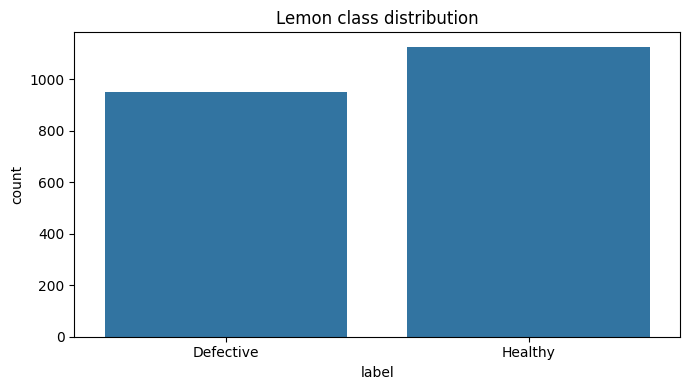

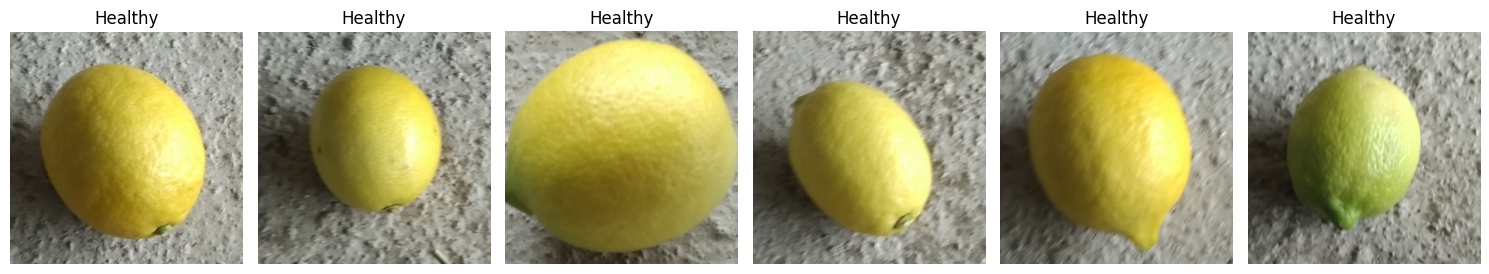

In [7]:
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
plt.figure(figsize=(7,4)); sns.countplot(data=df,x='label',order=sorted(df.label.unique())); plt.title('Lemon class distribution'); plt.tight_layout(); plt.show()
sample=df.sample(min(6,len(df)),random_state=42); fig,axs=plt.subplots(1,len(sample),figsize=(15,3))
if len(sample)==1: axs=[axs]
for ax,(_,r) in zip(axs,sample.iterrows()): ax.imshow(Image.open(r.path).convert('RGB')); ax.set_title(r.label); ax.axis('off')
plt.tight_layout(); plt.show()

## 7. TensorFlow input pipeline

In [8]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
IMG=(160,160); BATCH=32
classes=sorted(df.label.unique()); class_to_id={c:i for i,c in enumerate(classes)}
def read_img(path,label):
    x=tf.image.decode_image(tf.io.read_file(path),channels=3,expand_animations=False); x.set_shape([None,None,3]); return tf.image.resize(x,IMG),label
def make_ds(frame,training=False):
    y=frame.label.map(class_to_id).values.astype('int32'); ds=tf.data.Dataset.from_tensor_slices((frame.path.values,y))
    if training: ds=ds.shuffle(len(frame),seed=42)
    ds=ds.map(read_img,num_parallel_calls=tf.data.AUTOTUNE)
    if training:
        aug=keras.Sequential([layers.RandomFlip('horizontal'),layers.RandomRotation(.08),layers.RandomZoom(.1),layers.RandomContrast(.1)])
        ds=ds.map(lambda x,y:(aug(x,training=True),y),num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)
train_ds=make_ds(train_df,True); val_ds=make_ds(val_df); test_ds=make_ds(test_df)
print(classes)

['Defective', 'Healthy']


## 8. TinyLemonNet depthwise-separable CNN

In [9]:
def sep(x,f,s=1):
    x=layers.DepthwiseConv2D(3,strides=s,padding='same',use_bias=False)(x); x=layers.BatchNormalization()(x); x=layers.ReLU()(x)
    x=layers.Conv2D(f,1,use_bias=False)(x); x=layers.BatchNormalization()(x); return layers.ReLU()(x)
def build_model(n):
    inp=keras.Input((*IMG,3)); x=layers.Rescaling(1./255)(inp)
    x=layers.Conv2D(16,3,strides=2,padding='same',use_bias=False)(x); x=layers.BatchNormalization()(x); x=layers.ReLU()(x)
    x=sep(x,24); x=sep(x,32,2); x=sep(x,48,2); x=sep(x,64,2); x=layers.GlobalAveragePooling2D()(x); x=layers.Dropout(.25)(x)
    return keras.Model(inp,layers.Dense(n,activation='softmax')(x),name='TinyLemonNet')
model=build_model(len(classes)); model.summary()

Model: "TinyLemonNet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 80, 80, 16)     │           432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 80, 80, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 80, 80, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_conv2d                │ (None, 80, 80, 16)     │           144 │
│ (DepthwiseConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 80, 80, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 80, 80, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 80, 80, 24)     │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 80, 80, 24)     │            96 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 80, 80, 24)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_conv2d_1              │ (None, 40, 40, 24)     │           216 │
│ (DepthwiseConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 40, 40, 24)     │            96 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 40, 40, 24)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 40, 40, 32)     │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 40, 40, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 40, 40, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_conv2d_2              │ (None, 20, 20, 32)     │           288 │
│ (DepthwiseConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 20, 20, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_5 (ReLU)                  │ (None, 20, 20, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 8,618 (33.66 KB)

 Trainable params: 8,010 (31.29 KB)

 Non-trainable params: 608 (2.38 KB)

## 9. Train model

In [10]:
callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss',patience=10,restore_best_weights=True),keras.callbacks.ReduceLROnPlateau(monitor='val_loss',factor=.3,patience=4),keras.callbacks.ModelCheckpoint('/content/best_lemon.keras',monitor='val_loss',save_best_only=True)]
model.compile(optimizer=keras.optimizers.Adam(1e-3),loss='sparse_categorical_crossentropy',metrics=['accuracy'])
history=model.fit(train_ds,validation_data=val_ds,epochs=60,callbacks=callbacks)
model=keras.models.load_model('/content/best_lemon.keras')

Epoch 1/60
46/46 ━━━━━━━━━━━━━━━━━━━━ 36s 427ms/step - accuracy: 0.7901 - loss: 0.4514 - val_accuracy: 0.5434 - val_loss: 0.6893 - learning_rate: 0.0010
Epoch 2/60
46/46 ━━━━━━━━━━━━━━━━━━━━ 8s 183ms/step - accuracy: 0.9319 - loss: 0.1993 - val_accuracy: 0.5434 - val_loss: 0.6907 - learning_rate: 0.0010
Epoch 3/60
46/46 ━━━━━━━━━━━━━━━━━━━━ 8s 180ms/step - accuracy: 0.9601 - loss: 0.1266 - val_accuracy: 0.5434 - val_loss: 0.6919 - learning_rate: 0.0010
Epoch 4/60
46/46 ━━━━━━━━━━━━━━━━━━━━ 10s 180ms/step - accuracy: 0.9656 - loss: 0.1014 - val_accuracy: 0.5434 - val_loss: 0.6896 - learning_rate: 0.0010
Epoch 5/60
46/46 ━━━━━━━━━━━━━━━━━━━━ 10s 183ms/step - accuracy: 0.9697 - loss: 0.0943 - val_accuracy: 0.5531 - val_loss: 0.6864 - learning_rate: 0.0010
Epoch 6/60
46/46 ━━━━━━━━━━━━━━━━━━━━ 10s 184ms/step - accuracy: 0.9738 - loss: 0.0728 - val_accuracy: 0.6720 - val_loss: 0.6602 - learning_rate: 0.0010
Epoch 7/60
46/46 ━━━━━━━━━━━━━━━━━━━━ 8s 182ms/step - accuracy: 0.9787 - loss: 0.067

## 10. Training and validation curves

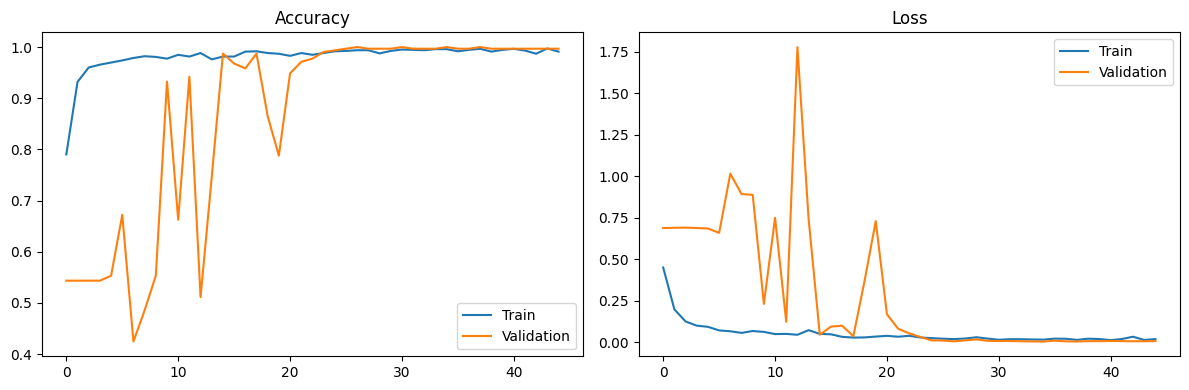

In [11]:
h=pd.DataFrame(history.history); fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].plot(h.accuracy,label='Train'); ax[0].plot(h.val_accuracy,label='Validation'); ax[0].set_title('Accuracy'); ax[0].legend()
ax[1].plot(h.loss,label='Train'); ax[1].plot(h.val_loss,label='Validation'); ax[1].set_title('Loss'); ax[1].legend(); plt.tight_layout(); plt.show()

## 11. Test metrics and confusion matrix

              precision    recall  f1-score   support

   Defective     1.0000    0.9860    0.9930       143
     Healthy     0.9883    1.0000    0.9941       169

    accuracy                         0.9936       312
   macro avg     0.9942    0.9930    0.9935       312
weighted avg     0.9937    0.9936    0.9936       312



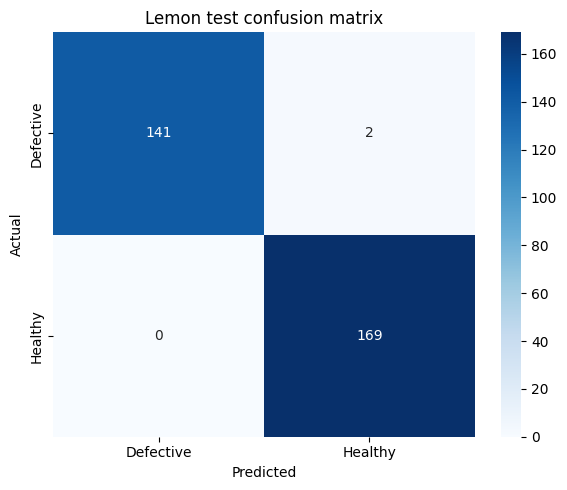

,Accuracy,Macro precision,Macro recall,Macro F1,Weighted F1
0,0.99359,0.994152,0.993007,0.993538,0.993586


In [12]:
from sklearn.metrics import classification_report,confusion_matrix,accuracy_score,precision_score,recall_score,f1_score
y_true=[]; y_prob=[]
for xb,yb in test_ds: y_prob.extend(model.predict(xb,verbose=0)); y_true.extend(yb.numpy())
y_true=np.array(y_true); y_prob=np.array(y_prob); y_pred=y_prob.argmax(1)
print(classification_report(y_true,y_pred,target_names=classes,digits=4,zero_division=0))
cm=confusion_matrix(y_true,y_pred); plt.figure(figsize=(6,5)); sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=classes,yticklabels=classes); plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('Lemon test confusion matrix'); plt.tight_layout(); plt.show()
metrics=pd.DataFrame([{'Accuracy':accuracy_score(y_true,y_pred),'Macro precision':precision_score(y_true,y_pred,average='macro',zero_division=0),'Macro recall':recall_score(y_true,y_pred,average='macro',zero_division=0),'Macro F1':f1_score(y_true,y_pred,average='macro',zero_division=0),'Weighted F1':f1_score(y_true,y_pred,average='weighted',zero_division=0)}]); display(metrics)

## 12. ROC and precision–recall curves

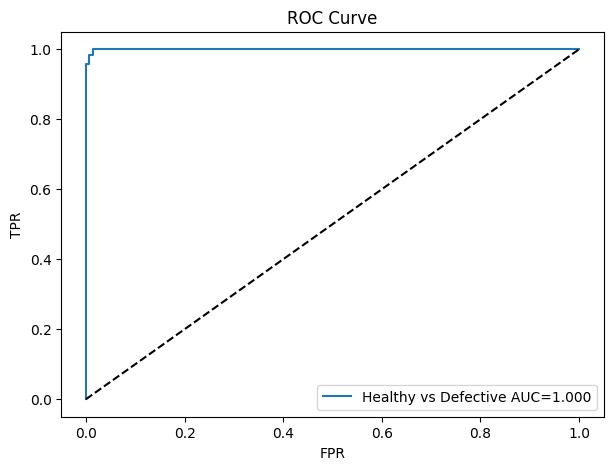

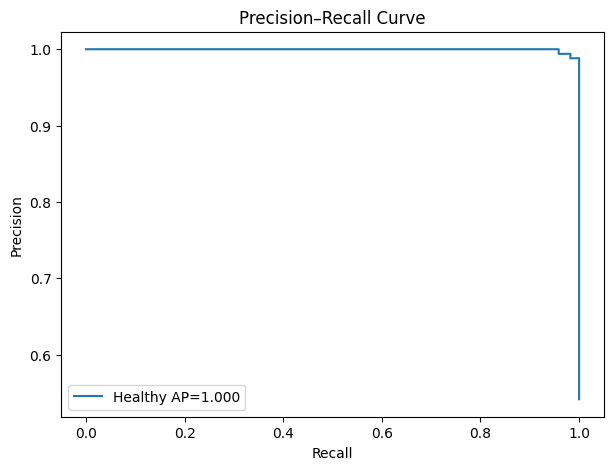

In [14]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve,auc,precision_recall_curve,average_precision_score

if len(classes) == 2:
    # Binary classification case
    fig, ax = plt.subplots(figsize=(7, 5))
    fpr, tpr, _ = roc_curve(y_true, y_prob[:, 1])
    ax.plot(fpr, tpr, label=f'{classes[1]} vs {classes[0]} AUC={auc(fpr, tpr):.3f}')
    ax.plot([0, 1], [0, 1], 'k--')
    ax.set(xlabel='FPR', ylabel='TPR', title='ROC Curve')
    ax.legend()
    plt.show()

    fig, ax = plt.subplots(figsize=(7, 5))
    p, r, _ = precision_recall_curve(y_true, y_prob[:, 1])
    ax.plot(r, p, label=f'{classes[1]} AP={average_precision_score(y_true, y_prob[:, 1]):.3f}')
    ax.set(xlabel='Recall', ylabel='Precision', title='Precision–Recall Curve')
    ax.legend()
    plt.show()
else:
    # Multiclass classification case
    Y = label_binarize(y_true, classes=np.arange(len(classes)))
    fig, ax = plt.subplots(figsize=(7, 5))
    for i, c in enumerate(classes):
        if len(np.unique(Y[:, i])) > 1:
            fpr, tpr, _ = roc_curve(Y[:, i], y_prob[:, i])
            ax.plot(fpr, tpr, label=f'{c} AUC={auc(fpr, tpr):.3f}')
    ax.plot([0, 1], [0, 1], 'k--')
    ax.set(xlabel='FPR', ylabel='TPR', title='One-vs-Rest ROC')
    ax.legend()
    plt.show()

    fig, ax = plt.subplots(figsize=(7, 5))
    for i, c in enumerate(classes):
        if len(np.unique(Y[:, i])) > 1:
            p, r, _ = precision_recall_curve(Y[:, i], y_prob[:, i])
            ax.plot(r, p, label=f'{c} AP={average_precision_score(Y[:, i], y_prob[:, i]):.3f}')
    ax.set(xlabel='Recall', ylabel='Precision', title='Precision–Recall')
    ax.legend()
    plt.show()

## 13. t-SNE feature visualization

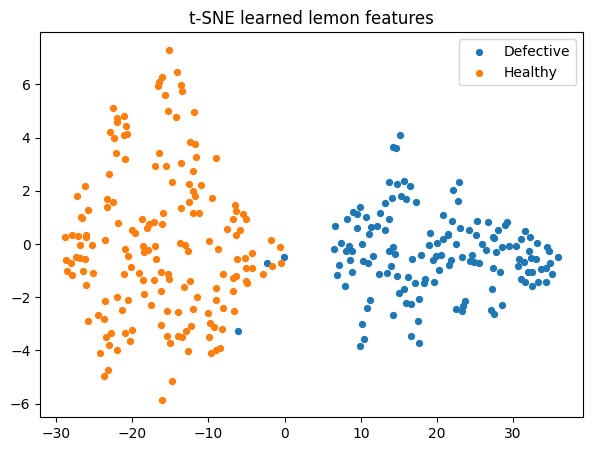

In [15]:
from sklearn.manifold import TSNE
fm=keras.Model(model.input,model.layers[-2].output); feats=[]
for xb,yb in test_ds: feats.append(fm.predict(xb,verbose=0))
F=np.concatenate(feats)
if len(F)>=5:
    Z=TSNE(n_components=2,perplexity=min(30,max(2,(len(F)-1)//3)),random_state=42,init='pca',learning_rate='auto').fit_transform(F)
    plt.figure(figsize=(7,5))
    for i,c in enumerate(classes): plt.scatter(Z[y_true==i,0],Z[y_true==i,1],s=18,label=c)
    plt.title('t-SNE learned lemon features'); plt.legend(); plt.show()

## 14. MobileNetV2 baseline

In [16]:
base=keras.applications.MobileNetV2(input_shape=(*IMG,3),include_top=False,weights='imagenet'); base.trainable=False
inp=keras.Input((*IMG,3)); x=keras.applications.mobilenet_v2.preprocess_input(inp); x=base(x,training=False); x=layers.GlobalAveragePooling2D()(x); x=layers.Dropout(.2)(x)
mb=keras.Model(inp,layers.Dense(len(classes),activation='softmax')(x)); mb.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])
mb.fit(train_ds,validation_data=val_ds,epochs=12,callbacks=[keras.callbacks.EarlyStopping(patience=4,restore_best_weights=True)])
print('MobileNetV2 test loss/accuracy:',mb.evaluate(test_ds,verbose=0))

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/12
46/46 ━━━━━━━━━━━━━━━━━━━━ 29s 428ms/step - accuracy: 0.8486 - loss: 0.3439 - val_accuracy: 0.9839 - val_loss: 0.1116
Epoch 2/12
46/46 ━━━━━━━━━━━━━━━━━━━━ 9s 191ms/step - accuracy: 0.9677 - loss: 0.1173 - val_accuracy: 0.9904 - val_loss: 0.0664
Epoch 3/12
46/46 ━━━━━━━━━━━━━━━━━━━━ 10s 190ms/step - accuracy: 0.9794 - loss: 0.0815 - val_accuracy: 0.9904 - val_loss: 0.0507
Epoch 4/12
46/46 ━━━━━━━━━━━━━━━━━━━━ 10s 190ms/step - accuracy: 0.9862 - loss: 0.0698 - val_accuracy: 0.9936 - val_loss: 0.0419
Epoch 5/12
46/46 ━━━━━━━━━━━━━━━━━━━━ 9s 189ms/step - accuracy: 0.9814 - loss: 0.0679 - val_accuracy: 0.9968 - val_loss: 0.0382
Epoch 6/12
46/46 ━━━━━━━━━━━━━━━━━━━━ 10s 191ms/step - accuracy: 0.9855 - loss: 0.0544 - val_accuracy: 0.9968 - val_loss: 0.0327
Epoch 7/12
46/46 ━━━━━━━━━━━━━━━━━━━━ 10s 189ms/step - accuracy: 0.9869 - loss: 0.0477 - val_accuracy: 0.9936 - val_loss: 0.0315
Epoch 8/12
46/46 ━━━━━━━━━━━━━━━━━━━━ 9s 191ms/ste

## 15. Model size and Colab inference latency

In [17]:
import time
model.save('/content/TinyLemonNet.keras'); sample=next(iter(test_ds))[0][:1]
for _ in range(10): model(sample,training=False).numpy()
times=[]
for _ in range(100):
    t=time.perf_counter(); model(sample,training=False).numpy(); times.append((time.perf_counter()-t)*1000)
resource=pd.DataFrame([{'Parameters':model.count_params(),'Keras file MB':os.path.getsize('/content/TinyLemonNet.keras')/1e6,'Colab batch-1 mean ms':np.mean(times),'Colab batch-1 p95 ms':np.percentile(times,95)}]); display(resource)
print('Colab latency is not MCU hardware latency.')

,Parameters,Keras file MB,Colab batch-1 mean ms,Colab batch-1 p95 ms
0,8618,0.23823,27.239566,29.397752


Colab latency is not MCU hardware latency.


## 16. INT8 post-training quantization

In [18]:
def representative_data():
    for x,y in train_ds.unbatch().take(200): yield [tf.cast(tf.expand_dims(x,0),tf.float32)]
converter=tf.lite.TFLiteConverter.from_keras_model(model); converter.optimizations=[tf.lite.Optimize.DEFAULT]; converter.representative_dataset=representative_data
converter.target_spec.supported_ops=[tf.lite.OpsSet.TFLITE_BUILTINS_INT8]; converter.inference_input_type=tf.int8; converter.inference_output_type=tf.int8
try:
    tflite=converter.convert(); open('/content/TinyLemonNet_INT8.tflite','wb').write(tflite); print('INT8 size KB:',len(tflite)/1024)
except Exception as e: print('INT8 conversion failed:',repr(e))

Saved artifact at '/tmp/tmp7vdrm8gp'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 160, 160, 3), dtype=tf.float32, name='input_layer_1')
Output Type:
  TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)
Captures:
  140680336080528: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140680336079760: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140680336078416: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140680336079376: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140680336079184: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140680336065360: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140680336079952: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140680336080336: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140680336078032: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140680336080720: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1406799774843

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


INT8 size KB: 25.7265625


## 17. Evaluate INT8 model

In [19]:
if os.path.exists('/content/TinyLemonNet_INT8.tflite'):
    it=tf.lite.Interpreter(model_path='/content/TinyLemonNet_INT8.tflite'); it.allocate_tensors(); ii=it.get_input_details()[0]; oi=it.get_output_details()[0]
    def lite_pred(x):
        a=x.numpy()
        if ii['dtype']==np.int8:
            s,z=ii['quantization']; a=np.round(a/s+z).clip(-128,127).astype(np.int8)
        it.set_tensor(ii['index'],a); it.invoke(); out=it.get_tensor(oi['index'])
        if oi['dtype']==np.int8:
            s,z=oi['quantization']; out=(out.astype(np.float32)-z)*s
        return out
    iy=[]; ip=[]
    for xb,yb in test_ds:
        for j in range(xb.shape[0]): iy.append(int(yb[j])); ip.append(int(np.argmax(lite_pred(xb[j:j+1])[0])))
    print(classification_report(iy,ip,target_names=classes,digits=4,zero_division=0))

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


              precision    recall  f1-score   support

   Defective     0.9930    0.9860    0.9895       143
     Healthy     0.9882    0.9941    0.9912       169

    accuracy                         0.9904       312
   macro avg     0.9906    0.9900    0.9903       312
weighted avg     0.9904    0.9904    0.9904       312



## 18. Export outputs

In [20]:
metrics.to_csv('/content/lemon_test_metrics.csv',index=False); resource.to_csv('/content/lemon_resource_metrics.csv',index=False)
pd.DataFrame({'true_label':[classes[i] for i in y_true],'predicted_label':[classes[i] for i in y_pred],'confidence':y_prob.max(1)}).to_csv('/content/lemon_predictions.csv',index=False)
from google.colab import files
for f in ['/content/TinyLemonNet.keras','/content/lemon_test_metrics.csv','/content/lemon_resource_metrics.csv','/content/lemon_predictions.csv']:
    if os.path.exists(f): files.download(f)
if os.path.exists('/content/TinyLemonNet_INT8.tflite'): files.download('/content/TinyLemonNet_INT8.tflite')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 19. Research reporting checklist
- Record dataset version, access date, license, class folder names and per-class image counts.
- Confirm whether labels mean healthy/rotten/quality grade or a specific pathological disease.
- Split original images before augmentation; audit exact and near duplicates across splits.
- Report per-class precision, recall, F1, macro-F1 and confusion matrix; repeat with multiple random seeds for stronger evidence.
- Compare TinyLemonNet and MobileNetV2 using the same held-out test set.
- Describe Colab timing as software latency only. For embedded claims, test the actual target MCU and report latency, RAM, flash and energy.
